# Activity 1: Dataset Preparation Activity
**Unit I – Foundations & Data Preparation** | 5 Marks

**Student:** Shreeyansh Mahamuni  
**Div:** B
**Roll NO:** AD3231

## Step 1: Load and inspect the dataset

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_raw = pd.read_csv("laptopData.csv")     # original data (never changed)
df = df_raw.copy()                         # working copy

print(df.shape)
df.head()

(1303, 12)


,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [44]:
df.tail()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
1298,1298.0,Lenovo,2 in 1 Convertible,14,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 6500U 2.5GHz,4GB,128GB SSD,Intel HD Graphics 520,Windows 10,1.8kg,33992.64
1299,1299.0,Lenovo,2 in 1 Convertible,13.3,IPS Panel Quad HD+ / Touchscreen 3200x1800,Intel Core i7 6500U 2.5GHz,16GB,512GB SSD,Intel HD Graphics 520,Windows 10,1.3kg,79866.72
1300,1300.0,Lenovo,Notebook,14,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,64GB Flash Storage,Intel HD Graphics,Windows 10,1.5kg,12201.12
1301,1301.0,HP,Notebook,15.6,1366x768,Intel Core i7 6500U 2.5GHz,6GB,1TB HDD,AMD Radeon R5 M330,Windows 10,2.19kg,40705.92
1302,1302.0,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,2.2kg,19660.32


In [45]:
print(df.columns)
df.info()

Index(['Unnamed: 0', 'Company', 'TypeName', 'Inches', 'ScreenResolution',
       'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight', 'Price'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1273 non-null   float64
 1   Company           1273 non-null   object 
 2   TypeName          1273 non-null   object 
 3   Inches            1273 non-null   object 
 4   ScreenResolution  1273 non-null   object 
 5   Cpu               1273 non-null   object 
 6   Ram               1273 non-null   object 
 7   Memory            1273 non-null   object 
 8   Gpu               1273 non-null   object 
 9   OpSys             1273 non-null   object 
 10  Weight            1273 non-null   object 
 11  Price             1273 non-null   float64
dtypes: float64(2), object(10)
memory usage: 122.3+ KB


## Step 2: Identify data types and basic statistics

In [46]:
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns
print("Numerical columns:", list(num_cols))
print("Categorical columns:", list(cat_cols))
df.describe()

Numerical columns: ['Unnamed: 0', 'Price']
Categorical columns: ['Company', 'TypeName', 'Inches', 'ScreenResolution', 'Cpu', 'Ram', 'Memory', 'Gpu', 'OpSys', 'Weight']


,Unnamed: 0,Price
count,1273.000000,1273.000000
mean,652.674784,59955.814073
std,376.493027,37332.251005
min,0.000000,9270.720000
25%,327.000000,31914.720000
50%,652.000000,52161.120000
75%,980.000000,79333.387200
max,1302.000000,324954.720000


In [47]:
# Look for suspicious values
print("Number of '?' in each column:")
print((df == "?").sum()) #counts the ? in every column

inches = df["Inches"].replace("?", np.nan).astype(float) # replaces the ? with a numeric copy of it
weight = df["Weight"].str.replace("kg", "").replace("?", np.nan).astype(float) # removes kg from weight column e.g 2kg to 2
print("\nInches min and max:", inches.min(), inches.max())
print("Weight min and max:", weight.min(), weight.max())

Number of '?' in each column:
Unnamed: 0          0
Company             0
TypeName            0
Inches              1
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              1
Gpu                 0
OpSys               0
Weight              1
Price               0
dtype: int64

Inches min and max: 10.1 35.6
Weight min and max: 0.0002 11.1


In [48]:
print("Screen sizes above 20 inches:")
df[inches > 20][["Company", "TypeName", "Inches", "Weight", "Price"]]

Screen sizes above 20 inches:


,Company,TypeName,Inches,Weight,Price
402,Lenovo,Notebook,25.6,2.1kg,60978.96
408,Lenovo,Notebook,35.6,2.2kg,21791.52
423,Asus,Notebook,35.6,2.3kg,31808.16
424,Dell,Gaming,27.3,4.42kg,149130.72
438,Lenovo,Ultrabook,24,1.32kg,126912.96
458,Microsoft,Ultrabook,33.5,1.25kg,95850.72
525,Lenovo,Notebook,24,2.02kg,71395.20
592,Dell,2 in 1 Convertible,31.6,1.39kg,32127.84
673,Lenovo,Notebook,35.6,2.2kg,18594.72


In [49]:
print("Weights below 0.3 kg or above 5 kg:")
df[(weight < 0.3) | (weight > 5)][["Company", "TypeName", "Inches", "Weight", "Price"]]

Weights below 0.3 kg or above 5 kg:


,Company,TypeName,Inches,Weight,Price
133,Acer,Notebook,15.6,7.2kg,30476.16
173,Toshiba,Notebook,15.6,5.4kg,26053.92
240,Lenovo,Notebook,15.6,7.2kg,31381.92
302,Lenovo,Notebook,17.3,5.8kg,34578.72
326,Acer,Notebook,15.6,8.23kg,29250.72
349,Dell,Ultrabook,15.6,0.0002kg,35324.64
587,Lenovo,Ultrabook,14,8.4kg,89137.44
630,Asus,Ultrabook,14,11.1kg,101232.00
656,Dell,Notebook,15.6,6.2kg,48964.32


## Step 3: Identify missing values

In [50]:
print(df.isnull().sum())
print()

Unnamed: 0          30
Company             30
TypeName            30
Inches              30
ScreenResolution    30
Cpu                 30
Ram                 30
Memory              30
Gpu                 30
OpSys               30
Weight              30
Price               30
dtype: int64



In [51]:
print("Completely empty rows:", df.isnull().all(axis=1).sum())
print("'?' in Inches, Weight, Memory:", (df["Inches"] == "?").sum(), (df["Weight"] == "?").sum(), (df["Memory"] == "?").sum())
print("Impossible screen sizes:", (inches > 20).sum())
print("Impossible weights:", ((weight < 0.3) | (weight > 5)).sum())

Completely empty rows: 30
'?' in Inches, Weight, Memory: 1 1 1
Impossible screen sizes: 9
Impossible weights: 9


In [52]:
df = df_raw.copy()

# 1. drop completely empty rows
df = df.dropna(how="all")
print("After dropping empty rows:", df.shape)

# 2. '?' becomes NaN, and units are removed so Inches and Weight become numbers
df = df.replace("?", np.nan)
df["Inches"] = df["Inches"].astype(float)
df["Weight_kg"] = df["Weight"].str.replace("kg", "").astype(float)
df = df.drop("Weight", axis=1)

# impossible values become NaN
df.loc[df["Inches"] > 20, "Inches"] = np.nan
df.loc[(df["Weight_kg"] < 0.3) | (df["Weight_kg"] > 5), "Weight_kg"] = np.nan

print("\nMissing values before filling:")
print(df.isnull().sum())

After dropping empty rows: (1273, 12)

Missing values before filling:
Unnamed: 0           0
Company              0
TypeName             0
Inches              10
ScreenResolution     0
Cpu                  0
Ram                  0
Memory               1
Gpu                  0
OpSys                0
Price                0
Weight_kg           10
dtype: int64


In [53]:
# 3. median for numbers, 4. mode for text
df["Inches"] = df["Inches"].fillna(df["Inches"].median())
df["Weight_kg"] = df["Weight_kg"].fillna(df["Weight_kg"].median())
df["Memory"] = df["Memory"].fillna(df["Memory"].mode()[0])

print("Missing values after filling:")
print(df.isnull().sum())

Missing values after filling:
Unnamed: 0          0
Company             0
TypeName            0
Inches              0
ScreenResolution    0
Cpu                 0
Ram                 0
Memory              0
Gpu                 0
OpSys               0
Price               0
Weight_kg           0
dtype: int64


## Step 4: Check duplicate records and consistency

In [54]:
df = df.drop("Unnamed: 0", axis=1)      # only a row number, so remove it before checking duplicates

print("Duplicate rows:", df.duplicated().sum())
df[df.duplicated()].head()

Duplicate rows: 29


,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Price,Weight_kg
1274,Asus,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,4GB,500GB HDD,Intel HD Graphics,Windows 10,19660.32,2.2
1275,Asus,Ultrabook,13.3,IPS Panel Full HD 1920x1080,Intel Core M 6Y30 0.9GHz,8GB,512GB SSD,Intel HD Graphics 515,Windows 10,38841.12,1.2
1276,Dell,Notebook,15.6,1366x768,Intel Core i3 7100U 2.4GHz,6GB,1TB HDD,Intel HD Graphics 620,Windows 10,24455.52,2.3
1277,Acer,Notebook,15.6,1366x768,Intel Celeron Dual Core N3060 1.6GHz,4GB,500GB HDD,Intel HD Graphics 400,Linux,15397.92,2.4
1278,Dell,Notebook,15.6,1366x768,Intel Celeron Dual Core N3050 1.6GHz,2GB,500GB HDD,Intel HD Graphics,Windows 10,20193.12,2.2


In [55]:
df = df.drop_duplicates()
print("Duplicate rows after removal:", df.duplicated().sum())
print("Shape:", df.shape)

Duplicate rows after removal: 0
Shape: (1244, 11)


In [56]:
# Check the category labels
df["Memory"] = df["Memory"].str.replace("  +", " ", regex=True)    # extra spaces

print(df["Company"].value_counts())
print()
print(df["TypeName"].value_counts())
print()
print(df["OpSys"].value_counts())

Company
Lenovo       282
Dell         281
HP           260
Asus         149
Acer         101
MSI           53
Toshiba       47
Apple         21
Samsung        9
Mediacom       7
Razer          7
Microsoft      6
Vero           4
Xiaomi         4
Chuwi          3
LG             3
Google         3
Huawei         2
Fujitsu        2
Name: count, dtype: int64

TypeName
Notebook              689
Gaming                203
Ultrabook             189
2 in 1 Convertible    112
Workstation            29
Netbook                22
Name: count, dtype: int64

OpSys
Windows 10      1022
No OS             63
Linux             57
Windows 7         45
Chrome OS         27
macOS             13
Mac OS X           8
Windows 10 S       8
Android            1
Name: count, dtype: int64


In [57]:
df["OpSys"] = df["OpSys"].replace("Mac OS X", "macOS")
df["OpSys"] = df["OpSys"].replace(["Windows 10", "Windows 7", "Windows 10 S"], "Windows")
print(df["OpSys"].value_counts())

OpSys
Windows      1075
No OS          63
Linux          57
Chrome OS      27
macOS          21
Android         1
Name: count, dtype: int64


In [58]:
df["Ram_GB"] = df["Ram"].str.replace("GB", "").astype(int)
df["Cpu_Brand"] = df["Cpu"].str.split().str[0]
df["Gpu_Brand"] = df["Gpu"].str.split().str[0]

df = df.drop(["Ram", "ScreenResolution", "Cpu", "Memory", "Gpu"], axis=1)
print(df.shape)
df.head()

(1244, 9)


,Company,TypeName,Inches,OpSys,Price,Weight_kg,Ram_GB,Cpu_Brand,Gpu_Brand
0,Apple,Ultrabook,13.3,macOS,71378.6832,1.37,8,Intel,Intel
1,Apple,Ultrabook,13.3,macOS,47895.5232,1.34,8,Intel,Intel
2,HP,Notebook,15.6,No OS,30636.0000,1.86,8,Intel,Intel
3,Apple,Ultrabook,15.4,macOS,135195.3360,1.83,16,Intel,AMD
4,Apple,Ultrabook,13.3,macOS,96095.8080,1.37,8,Intel,Intel


## Step 5: Basic EDA

In [59]:
df[["Inches", "Ram_GB", "Weight_kg", "Price"]].describe()

,Inches,Ram_GB,Weight_kg,Price
count,1244.000000,1244.000000,1244.000000,1244.000000
mean,15.032797,8.528135,2.047106,60606.224427
std,1.422993,5.586878,0.673626,37424.636161
min,10.100000,1.000000,0.690000,9270.720000
25%,14.000000,4.000000,1.500000,32655.445200
50%,15.600000,8.000000,2.040000,52693.920000
75%,15.600000,8.000000,2.310000,79813.440000
max,18.400000,64.000000,4.700000,324954.720000


In [60]:
print(df["TypeName"].value_counts())
print()
print(df["Company"].value_counts())

TypeName
Notebook              689
Gaming                203
Ultrabook             189
2 in 1 Convertible    112
Workstation            29
Netbook                22
Name: count, dtype: int64

Company
Lenovo       282
Dell         281
HP           260
Asus         149
Acer         101
MSI           53
Toshiba       47
Apple         21
Samsung        9
Mediacom       7
Razer          7
Microsoft      6
Vero           4
Xiaomi         4
Chuwi          3
LG             3
Google         3
Huawei         2
Fujitsu        2
Name: count, dtype: int64


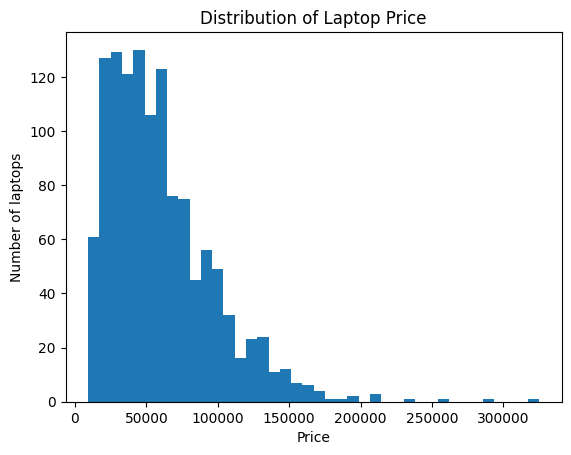

Skewness of Price: 1.52


In [61]:
# Graph 1: Histogram of Price
plt.hist(df["Price"], bins=40)
plt.title("Distribution of Laptop Price")
plt.xlabel("Price")
plt.ylabel("Number of laptops")
plt.show()

print("Skewness of Price:", round(df["Price"].skew(), 2))

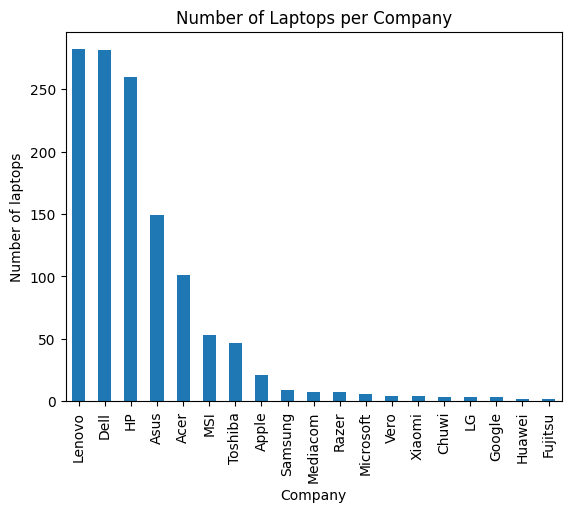

In [62]:
# Graph 2: Bar chart of laptops per company
df["Company"].value_counts().plot(kind="bar")
plt.title("Number of Laptops per Company")
plt.xlabel("Company")
plt.ylabel("Number of laptops")
plt.show()

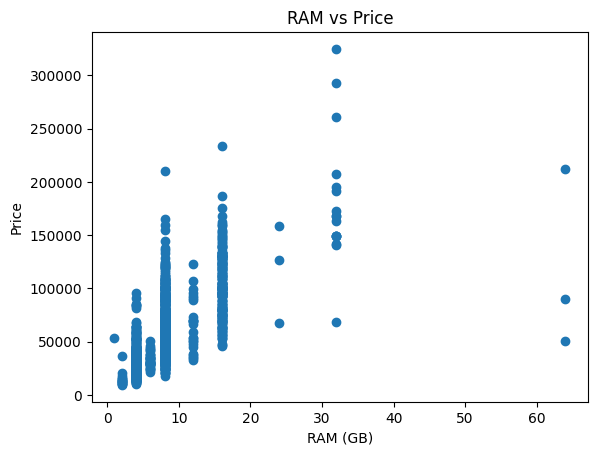

In [63]:
# Graph 3: Scatter plot of RAM and Price
plt.scatter(df["Ram_GB"], df["Price"])
plt.title("RAM vs Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Price")
plt.show()

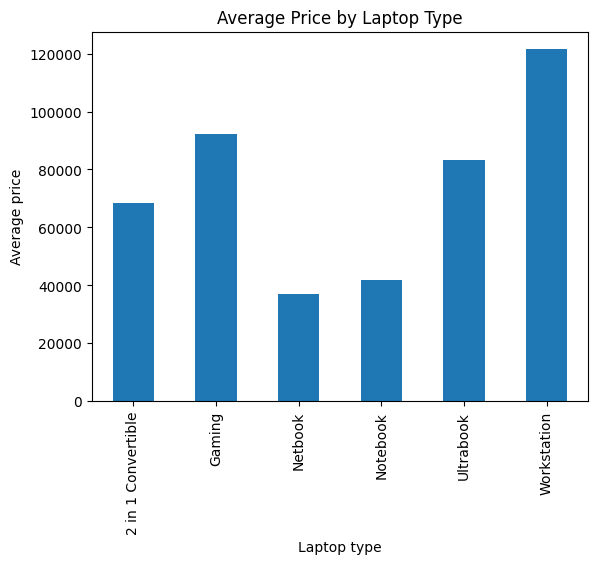

Inches       0.064094
Ram_GB       0.681922
Weight_kg    0.218165
Price        1.000000
Name: Price, dtype: float64


In [64]:
# Graph 4: Average price by laptop type
df.groupby("TypeName")["Price"].mean().plot(kind="bar")
plt.title("Average Price by Laptop Type")
plt.xlabel("Laptop type")
plt.ylabel("Average price")
plt.show()

print(df[["Inches", "Ram_GB", "Weight_kg", "Price"]].corr()["Price"])

## Step 6: Encode categorical features

In [65]:
df.to_csv("laptop_cleaned.csv", index=False)      # cleaned data before encoding and scaling

print("Before encoding:", df.shape)
df[["Company", "TypeName", "OpSys", "Cpu_Brand", "Gpu_Brand"]].head()

Before encoding: (1244, 9)


,Company,TypeName,OpSys,Cpu_Brand,Gpu_Brand
0,Apple,Ultrabook,macOS,Intel,Intel
1,Apple,Ultrabook,macOS,Intel,Intel
2,HP,Notebook,No OS,Intel,Intel
3,Apple,Ultrabook,macOS,Intel,AMD
4,Apple,Ultrabook,macOS,Intel,Intel


In [66]:
df = pd.get_dummies(df, columns=["Company", "TypeName", "OpSys", "Cpu_Brand", "Gpu_Brand"], dtype=int)

print("After encoding:", df.shape)
df.head()

After encoding: (1244, 42)


,Inches,Price,Weight_kg,Ram_GB,Company_Acer,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,...,OpSys_No OS,OpSys_Windows,OpSys_macOS,Cpu_Brand_AMD,Cpu_Brand_Intel,Cpu_Brand_Samsung,Gpu_Brand_AMD,Gpu_Brand_ARM,Gpu_Brand_Intel,Gpu_Brand_Nvidia
0,13.3,71378.6832,1.37,8,0,1,0,0,0,0,...,0,0,1,0,1,0,0,0,1,0
1,13.3,47895.5232,1.34,8,0,1,0,0,0,0,...,0,0,1,0,1,0,0,0,1,0
2,15.6,30636.0000,1.86,8,0,0,0,0,0,0,...,1,0,0,0,1,0,0,0,1,0
3,15.4,135195.3360,1.83,16,0,1,0,0,0,0,...,0,0,1,0,1,0,1,0,0,0
4,13.3,96095.8080,1.37,8,0,1,0,0,0,0,...,0,0,1,0,1,0,0,0,1,0


Every category became its own 0/1 column. For example, `TypeName` turned into `TypeName_Gaming`, `TypeName_Notebook`, `TypeName_Ultrabook` and so on.

## Step 7: Scale numerical features


In [67]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("Price", axis=1)
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (995, 41)
X_test : (249, 41)
y_train: (995,)
y_test : (249,)


In [68]:
num_cols = ["Inches", "Ram_GB", "Weight_kg"]

print("Before scaling (train):")
X_train[num_cols].describe().round(2)

Before scaling (train):


,Inches,Ram_GB,Weight_kg
count,995.00,995.00,995.00
mean,15.03,8.70,2.05
std,1.40,5.84,0.68
min,10.10,1.00,0.69
25%,14.00,4.00,1.54
50%,15.60,8.00,2.04
75%,15.60,8.00,2.30
max,18.40,64.00,4.70


In [69]:
X_train = X_train.copy()
X_test = X_test.copy()

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])    # learn from train only
X_test[num_cols] = scaler.transform(X_test[num_cols])          # use the same values on test

print("After scaling (train): mean is about 0 and std is about 1")
X_train[num_cols].describe().round(2)

After scaling (train): mean is about 0 and std is about 1


,Inches,Ram_GB,Weight_kg
count,995.00,995.00,995.00
mean,0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-3.52,-1.32,-1.99
25%,-0.74,-0.80,-0.74
50%,0.40,-0.12,-0.01
75%,0.40,-0.12,0.37
max,2.40,9.48,3.90


## Step 8: Save the prepared dataset

In [70]:
train = X_train.copy()
train["Price"] = y_train
train["split"] = "train"

test = X_test.copy()
test["Price"] = y_test
test["split"] = "test"

final = pd.concat([train, test])

print("Final shape:", final.shape)
print("Missing values:", final.isnull().sum().sum())
print("Duplicate rows:", final.duplicated().sum())

Final shape: (1244, 43)
Missing values: 0
Duplicate rows: 4


In [71]:
final.to_csv("laptop_prepared.csv", index=False)
print("Saved as laptop_prepared.csv (the original laptopData.csv is unchanged)")
final.head()

Saved as laptop_prepared.csv (the original laptopData.csv is unchanged)


,Inches,Weight_kg,Ram_GB,Company_Acer,Company_Apple,Company_Asus,Company_Chuwi,Company_Dell,Company_Fujitsu,Company_Google,...,OpSys_macOS,Cpu_Brand_AMD,Cpu_Brand_Intel,Cpu_Brand_Samsung,Gpu_Brand_AMD,Gpu_Brand_ARM,Gpu_Brand_Intel,Gpu_Brand_Nvidia,Price,split
315,0.403487,0.418149,-0.119375,0,0,0,0,1,0,0,...,0,0,1,0,1,0,0,0,44968.32,train
1250,0.403487,0.226967,-0.804960,0,0,0,0,1,0,0,...,0,0,1,0,0,0,1,0,17262.72,train
1004,-1.235747,-1.243660,-0.804960,0,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,63669.60,train
560,-2.447356,-1.170128,-0.804960,1,0,0,0,0,0,0,...,0,0,1,0,0,0,1,0,18594.72,train
99,0.403487,0.844631,0.566211,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,66546.72,train


## Conclusion
**Problems found**
- The file had 1,303 rows, but **30 were completely empty** (the 2.3% missing in every column).
- **Hidden missing values** written as `?` in `Inches`, `Weight` and `Memory`.
- **Impossible values:** 9 screen sizes above 20 inches (for example 35.6) and 9 weights outside 0.3 to 5 kg (for example 0.0002 kg and 11.1 kg).
- **29 exact duplicate rows**, hidden by the row-number column.
- **Messy data:** numbers stored as text with units (`8GB`, `1.37kg`), extra spaces in `Memory`, and `macOS` / `Mac OS X` as two names for one operating system.

**What I did**
- Dropped the 30 empty rows and the row-number column, and removed the 29 duplicate copies.
- Changed `?` and impossible values to missing values and filled 21 of them with the **median** (`Inches`, `Weight_kg`) or the **mode** (`Memory`). Real unusual values (such as 64 GB RAM) were checked and kept.
- Converted `Ram` and `Weight` to numbers, kept only the brand from `Cpu` and `Gpu`, and removed the long text columns (`ScreenResolution`, `Cpu`, `Memory`, `Gpu`).
- Used **one-hot encoding** (`pd.get_dummies`) for the five nominal columns.
- Split the data into 80% train and 20% test, and used **StandardScaler** on `Inches`, `Ram_GB` and `Weight_kg`, fitted on the training data only. `Price` (target) and the 0/1 columns were not scaled.

**Result:** `laptop_prepared.csv` has **1,244 rows and 43 columns** (41 input columns, `Price` and a `split` column showing train/test) with **no missing values**. The final check shows 4 pairs of identical rows. In the raw data these rows were different (details like exact CPU model, screen resolution or storage, which I removed when simplifying the columns), so they are different laptops and not unwanted copies, and I keep them. `laptop_cleaned.csv` (before encoding and scaling) is also saved, and the original `laptopData.csv` is unchanged.